# 7d. Recharge-oscillator dynamics: E3SM, XRO and observations

Last of the four XRO notebooks (7a validation → 7b events → 7c E3SM state → **7d recharge**).
7c showed E3SM starting with lower equatorial recharge *h* than EN4 while warming as fast as or
faster than observed. This notebook separates the two candidate explanations:

* **Different initial state.** Would XRO, started from E3SM's initial offsets instead of the
  observed state, forecast what E3SM forecasts? (Section 2, "matched-initial-state" XRO.)
* **Different dynamics.** Does E3SM's *T*-*h* trajectory turn differently from the observed and
  XRO trajectories? (Section 1, phase planes; see also 7c section 4.)

**Caveats.** *h* is the equatorial Pacific OHC700 recharge proxy (not WWV), and the E3SM-EN4
start-month *h* difference may partly be a difference between the CFSR ocean analysis and EN4 or
a 0 K-referenced heat-content term (see 7c). Neither section measures a specific feedback (e.g.
Bjerknes); that needs wind and thermocline diagnostics. Regressing tendencies on *T* and *h* along
one forecast year to estimate recharge-oscillator coefficients was tried and dropped: applied to
XRO's own forecasts it did not recover XRO's fitted coefficients (one trajectory is too short and
*T*, *h* too collinear).

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

from util import rtenso_case as rc
from util import xro_case as xc
from util import pubfig as pf

pf.use_style()

### Run controls

In [2]:
NOTEBOOK = "7d_e3sm_recharge"
derivation_mode = "auto"
CLIM_METHOD = "lead_drift"
PHASE_MONTHS = 24          # months shown in the phase planes (from XRO's initial month)
LO, HI = xc.XRO_SETUP["spread"]
OUTDIR = rc.output_dir(NOTEBOOK, "data")
print("figures ->", rc.figure_dir(NOTEBOOK))

figures -> /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7d_e3sm_recharge/figures


In [3]:
%%time
X = xc.obs_state(mode=derivation_mode)
FITS = {year: xc.fit_xro(X, event["train"]) for year, event in xc.EVENTS.items()}
XRO_FC = {(year, init): fc for year, event in xc.EVENTS.items() for init in event["init_months"]
          if (fc := xc.event_forecast(FITS[year], year, init)) is not None}
FC_X = xc.hindcast_states(method=CLIM_METHOD, mode=derivation_mode, verbose=False)
STARTS = sorted({(y, i) for (y, _, i) in FC_X})


def cases_for(year, init):
    return [case for case in xc.CASES if (year, case, init) in FC_X]


def distinct_members(year, init):
    """All members of the distinct runs of a start (identical runs, e.g. Feb 2026 CLIM/OBS, once)."""
    seen, out = [], []
    for case in cases_for(year, init):
        ds = FC_X[(year, case, init)]
        if any(ds.identical(s) or bool((ds["Nino34"] == s["Nino34"]).all()) for s in seen):
            continue
        seen.append(ds)
        out.append(ds.drop_vars("time").assign_coords(member=[f"{case}:{m}" for m in ds["member"].values]))
    return xr.concat(out, dim="member").assign_coords(time=FC_X[(year, cases_for(year, init)[0], init)]["time"])

CPU times: user 2.64 s, sys: 710 ms, total: 3.35 s
Wall time: 22.6 s


## 1. *T*-*h* phase planes

Niño3.4 (*T*) against *h* from XRO's initial month (the month before the start) for
`PHASE_MONTHS` months. The recharge oscillator turns clockwise: recharge (*h* > 0) leads warming,
the warm event discharges *h*, and *h* < 0 leads cooling. Lines: observed (black), each case's
ensemble mean, XRO (purple dashed). Small markers every month, larger every 3 months; stars mark
the first point; observed months are labelled every 6 months.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7d_e3sm_recharge/figures/fig_xro_y2015_phase_planes.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7d_e3sm_recharge/figures/fig_xro_y2015_phase_planes.png


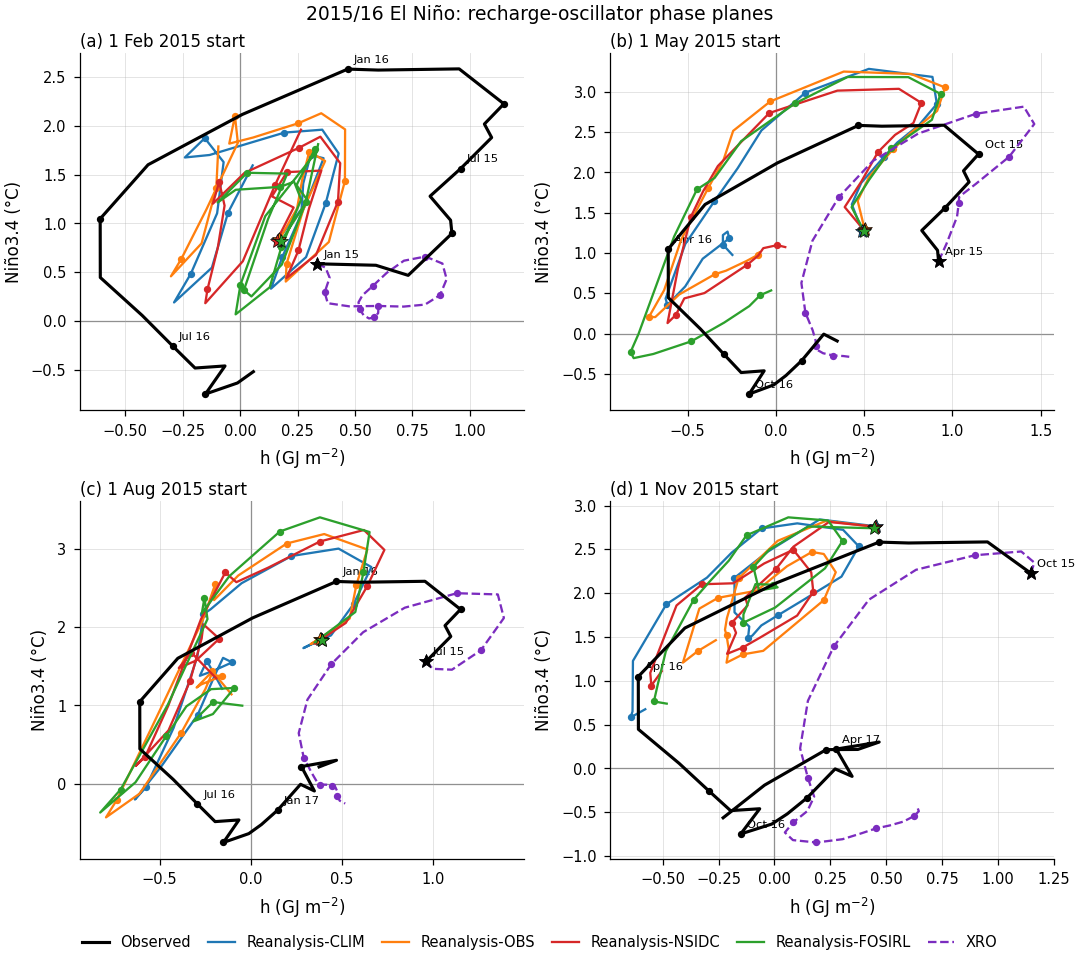

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7d_e3sm_recharge/figures/fig_xro_y2026_phase_planes.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7d_e3sm_recharge/figures/fig_xro_y2026_phase_planes.png


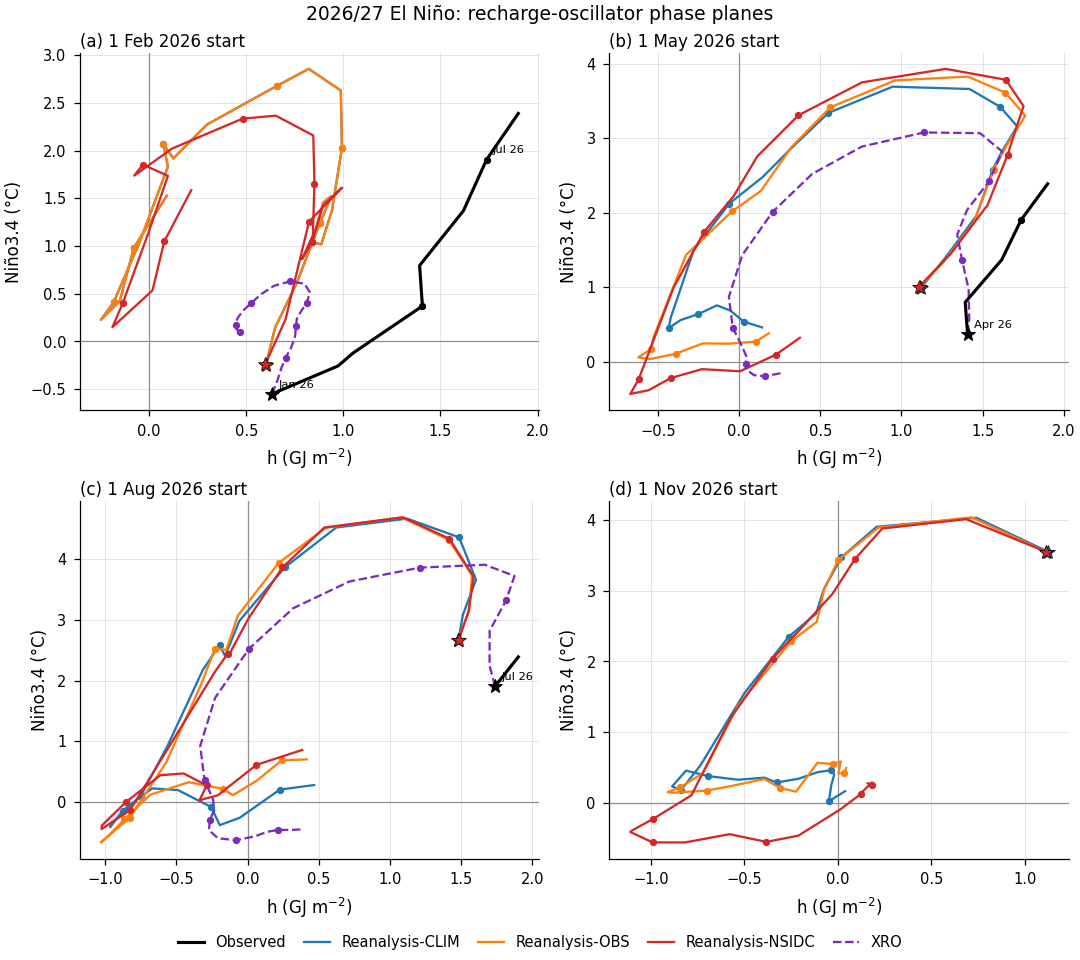

In [4]:
def phase_line(ax, h, t, color, label, lw=1.1, ls="-", zorder=3):
    ax.plot(h, t, color=color, lw=lw, ls=ls, label=label, zorder=zorder)
    ax.plot(h[::3], t[::3], ls="none", marker="o", ms=2.5, color=color, zorder=zorder)
    ax.plot(h[:1], t[:1], ls="none", marker="*", ms=7, color=color, mec="k", mew=0.3, zorder=zorder + 1)


def plot_phase(year):
    inits = [i for (y, i) in STARTS if y == year]
    ncol = 2 if len(inits) == 4 else len(inits)
    nrow = int(np.ceil(len(inits) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(pf.WIDTH["double"], 3.0 * nrow + 0.4), squeeze=False)
    for k, (ax, init) in enumerate(zip(axes.flat, inits)):
        ic = xc.add_months(year, init, -1)
        end = xc.add_months(*ic, PHASE_MONTHS - 1)
        obs = X.sel(time=slice(f"{ic[0]}-{ic[1]:02d}", f"{end[0]}-{end[1]:02d}")).dropna("time", subset=["Nino34", "WWV"])
        phase_line(ax, obs["WWV"].values, obs["Nino34"].values, "k", "Observed", lw=1.5, zorder=6)
        for tm, hh, tt in list(zip(obs["time"].values, obs["WWV"].values, obs["Nino34"].values))[::6]:
            ax.annotate(f"{xc.MONTH_NAMES[tm.month]} {str(tm.year)[2:]}", (hh, tt), xytext=(3, 3),
                        textcoords="offset points", fontsize=5.5)
        for case in cases_for(year, init):
            m = FC_X[(year, case, init)].mean("member").sel(lead=slice(0, PHASE_MONTHS - 2))
            phase_line(ax, m["WWV"].values, m["Nino34"].values, xc.CASES[case]["color"], case)
        if (year, init) in XRO_FC:
            d = XRO_FC[(year, init)]["det"].sel(lead=slice(-1, PHASE_MONTHS - 2))
            phase_line(ax, d["WWV"].values, d["Nino34"].values, xc.XRO_STYLE["color"], "XRO", ls="--")
        pf.zero_line(ax)
        pf.zero_line(ax, axis="x")
        ax.grid(True)
        ax.set_xlabel(f"h ({xc.UNITS['WWV']})")
        ax.set_ylabel("Niño3.4 (°C)")
        pf.panel_label(ax, k, f"1 {xc.MONTH_NAMES[init]} {year} start")
    for ax in axes.flat[len(inits):]:
        ax.set_visible(False)
    fig.suptitle(f"{xc.EVENTS[year]['label']}: recharge-oscillator phase planes")
    pf.legend_below(fig, ax=axes.flat[0], ncol=6)
    return fig


for year in xc.EVENTS:
    fig = plot_phase(year)
    pf.save(fig, NOTEBOOK, "xro", f"y{year}", "phase_planes")
    plt.show()

## 2. XRO started from E3SM's initial offsets

For each start, δ = E3SM start-month value (mean of the distinct runs' ensemble means) minus the
observed value of the same month, added to XRO's observed initial state:

* **h matched:** only δ*h*;
* **state matched:** δ for all ten variables.

If "state matched" XRO reproduces E3SM's peak, the E3SM-XRO difference comes from the initial
state (or from the E3SM-observation reference difference at lead 0); if it stays near the control
XRO, it comes from E3SM's evolution. The last columns give the share of the E3SM-XRO difference
reproduced by each matched experiment. Read with 7a section 6: XRO's ensemble mean is typically
too weak for strong events from Feb and May.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7d_e3sm_recharge/figures/fig_xro_matched_initial_state.pdf


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/7d_e3sm_recharge/figures/fig_xro_matched_initial_state.png


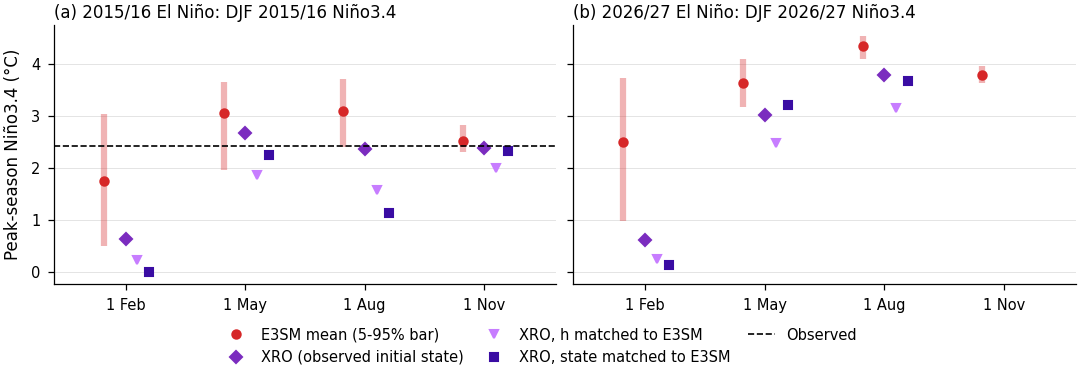

observed  E3SM mean  E3SM 5%  E3SM 95%  delta h  \
event           start                                                         
2015/16 El Niño 1 Feb 2015      2.42       1.76     0.49      3.04    -0.42   
                1 May 2015      2.42       3.07     1.97      3.67    -0.42   
                1 Aug 2015      2.42       3.09     2.40      3.72    -0.71   
                1 Nov 2015      2.42       2.52     2.31      2.83    -0.50   
2026/27 El Niño 1 Feb 2026       NaN       2.50     0.98      3.73    -0.37   
                1 May 2026       NaN       3.64     3.17      4.11    -0.28   
                1 Aug 2026       NaN       4.36     4.10      4.54    -0.42   
                1 Nov 2026       NaN       3.79     3.63      3.96      NaN   

                             XRO  XRO h matched  XRO state matched  \
event           start                                                
2015/16 El Niño 1 Feb 2015  0.62           0.23              -0.01   
                1 May 2015  2.67           1.85               2.25   
                1 Aug 2015  2.37           1.58               1.13   
                1 Nov 2015  2.39           2.00               2.32   
2026/27 El Niño 1 Feb 2026  0.61           0.25               0.12   
                1 May 2026  3.01           2.47               3.21   
                1 Aug 2026  3.80           3.15               3.67   
                1 Nov 2026   NaN            NaN                NaN   

                            share of gap (h)  share of gap (state)  
event           start                                               
2015/16 El Niño 1 Feb 2015             -0.35                 -0.56  
                1 May 2015             -2.09                 -1.09  
                1 Aug 2015             -1.09                 -1.71  
                1 Nov 2015             -3.02                 -0.57  
2026/27 El Niño 1 Feb 2026             -0.19                 -0.26  
                1 May 2026             -0.87                  0.31  
                1 Aug 2026             -1.16                 -0.22  
                1 Nov 2026               NaN                   NaN

In [5]:
mt_rows = []
for (year, init) in STARTS:
    months = xc.EVENTS[year]["peak_season"]["months"]
    ens = distinct_members(year, init)
    lead0 = ens.isel(lead=0).mean("member")
    obs0 = {v: xc.obs_value(X, v, year, init) for v in xc.XRO_VARS}
    delta = {v: float(lead0[v]) - obs0[v] for v in xc.XRO_VARS}
    e3sm = rc.target_mean(ens["Nino34"], months)
    row = {"event": xc.EVENTS[year]["label"], "start": f"1 {xc.MONTH_NAMES[init]} {year}",
           "observed": float(rc.obs_target_mean(X["Nino34"], months)),
           "E3SM mean": float(e3sm.mean("member")), f"E3SM {LO}%": float(e3sm.quantile(LO / 100, "member")),
           f"E3SM {HI}%": float(e3sm.quantile(HI / 100, "member")), "delta h": delta["WWV"]}
    if (year, init) in XRO_FC:
        row["XRO"] = float(rc.target_mean(XRO_FC[(year, init)]["det"]["Nino34"], months))
        if np.isfinite(delta["WWV"]):
            row["XRO h matched"] = float(rc.target_mean(xc.perturbed_forecast(FITS[year], year, init, {"WWV": delta["WWV"]})["Nino34"], months))
        if all(np.isfinite(list(delta.values()))):
            row["XRO state matched"] = float(rc.target_mean(xc.perturbed_forecast(FITS[year], year, init, delta)["Nino34"], months))
    mt_rows.append(row)
matched = pd.DataFrame(mt_rows)
gap = matched["E3SM mean"] - matched["XRO"]
for col in ("XRO h matched", "XRO state matched"):
    if col in matched:
        matched[f"share of gap ({col.split()[1]})"] = (matched[col] - matched["XRO"]) / gap
matched.round(2).to_csv(OUTDIR / "XRO_matched_initial_state_peak_nino34.csv", index=False)

fig, axes = plt.subplots(1, len(xc.EVENTS), figsize=(pf.WIDTH["double"], 2.5), sharey=True,
                         gridspec_kw={"width_ratios": [sum(1 for (y, _) in STARTS if y == yr) for yr in xc.EVENTS]})
marks = {"XRO": ("D", xc.XRO_STYLE["color"], "XRO (observed initial state)"),
         "XRO h matched": ("v", "#c77dff", "XRO, h matched to E3SM"),
         "XRO state matched": ("s", "#3a0ca3", "XRO, state matched to E3SM")}
for p, (ax, year) in enumerate(zip(np.atleast_1d(axes), xc.EVENTS)):
    sub = matched[matched["event"] == xc.EVENTS[year]["label"]].reset_index(drop=True)
    xpos = np.arange(len(sub))
    ax.vlines(xpos - 0.18, sub[f"E3SM {LO}%"], sub[f"E3SM {HI}%"], color="#d62728", lw=3, alpha=0.35)
    ax.plot(xpos - 0.18, sub["E3SM mean"], "o", color="#d62728", ms=4, label=f"E3SM mean ({LO}-{HI}% bar)")
    for off, (col, (mk, color, label)) in zip((0.0, 0.1, 0.2), marks.items()):
        if col in sub:
            ax.plot(xpos + off, sub[col], mk, color=color, ms=4, label=label)
    if np.isfinite(sub["observed"]).any():
        ax.axhline(sub["observed"].iloc[0], color="k", ls="--", lw=0.8, label="Observed")
    ax.set_xticks(xpos, [s.replace(f" {year}", "") for s in sub["start"]])
    ax.set_xlim(-0.6, len(sub) - 0.4)
    ax.grid(axis="y")
    pf.panel_label(ax, p, f"{xc.EVENTS[year]['label']}: {xc.EVENTS[year]['peak_season']['label']} Niño3.4")
np.atleast_1d(axes)[0].set_ylabel("Peak-season Niño3.4 (°C)")
handles, labels = np.atleast_1d(axes)[0].get_legend_handles_labels()
pf.legend_below(fig, handles, labels, ncol=3)
pf.save(fig, NOTEBOOK, "xro", "matched_initial_state")
plt.show()
display(matched.set_index(["event", "start"]).round(2))